# DSA211 — Predicting Online Purchases
### Topic 2 · Classification System Evaluation · Voucher revenue revision

**Objective.** Predict whether an online browsing session ends in a purchase (`Revenue = 1`) and assess a model-guided voucher policy under explicit hypothetical assumptions. This is a prediction exercise, not causal inference.

The statistical decision is `predicted Buy (1) → no voucher`; `predicted No Buy (0) → voucher`. The dataset contains session outcomes without this intervention. Its labels are never changed by the simulation.

**Four assumptions.** (A1) Every voucher is redeemed and converts a session with certainty. (A2) The voucher discounts the order by 20%, with no minimum spend. (A3) Every order has the same representative value `A`, so it cancels from relative revenue. (A4) Recorded labels describe behaviour without the proposed intervention. These are assumptions, not findings. We report simulated sales revenue, not profit; we do not assign a numerical value to `A`.

The analysis compares exactly two business scenarios: the observed no-voucher baseline and the model-guided voucher policy. It does not estimate an actual causal lift.

## 0. Methodology and decision rules

**Objective.** Select a session classifier and training-only probability threshold that maximize simulated revenue under A1–A4, while reporting model discrimination separately.

**Methodology.** Keep the established stratified 75/25 train/test split (`random_state=42`) and stratified five-fold CV on training data. Fit every imputer, encoder, transform and scaler within each fold. The historical test partition is evaluated once after choosing a candidate and its threshold from training out-of-fold (OOF) predictions; it has been viewed in the earlier project and is not a fresh independent holdout.

**First-pass requirement.** Attempt Logistic Regression, Gaussian Naive Bayes, LDA and default QDA with all 17 original predictors. Preserve genuine failures and warnings. After this diagnostic stage, use all 16 predictors other than `PageValues` for operational candidates because `PageValues` may be recorded after the purchase decision. This is a prediction-time availability judgment, not a conclusion from AUC alone.

**Revenue rule.** For calibrated purchase probability `p`, no-voucher expected revenue is `pA`; voucher revenue under A1–A3 is `0.80A`. Issue a voucher when `p < 0.80`, so the theoretical threshold is **0.80**. This gives opportunity costs `C_FP = 0.80A` (missed discounted sale) and `C_FN = 0.20A` (discount on a purchase that would have happened), hence `C_FN:C_FP = 1:4`. These are not measured losses.

With positive class `Revenue=1`, `R0 = TP + FN` and `Rmodel = TP + 0.80(FN + TN)` in units of `A`. Thus `ΔR = 0.80TN − 0.20FN`, relative change is `ΔR/R0`, and improvement requires `4TN > FN`. The labels remain as observed; only simulated business outcomes differ.

**Revenue equations (in units of `A`).** The cost ratio and threshold follow from the two expected revenues:

$$
\begin{aligned}
C_{FP} &= 0.80A, & C_{FN} &= 0.20A, & C_{FN}:C_{FP} &= 1:4,\\
pA &\geq 0.80A \Longleftrightarrow p \geq 0.80 && \Rightarrow \text{no voucher},\\
t^* &= \frac{C_{FP}}{C_{FP}+C_{FN}} = 0.80.
\end{aligned}
$$

For confusion-matrix counts with `Revenue = 1` as positive:

$$
\begin{aligned}
R_0 &= A(TP+FN),\\
R_{\mathrm{model}} &= A[TP+0.80(FN+TN)],\\
\Delta R &= A(0.80TN-0.20FN),\\
\frac{\Delta R}{R_0} &= \frac{0.80TN-0.20FN}{TP+FN},\\
\Delta R>0 &\Longleftrightarrow 4TN>FN.
\end{aligned}
$$

**Implication.** The theoretical cutoff recommends no voucher for probabilities at or above 0.80 and a voucher below it; threshold comparisons therefore change the assumed policy allocation, not the observed labels.

**Selection.** On each eligible operational candidate, scan exact OOF score cutpoints, including 0, 0.80, 1 and a cutoff above the maximum score. Choose the model and cutoff with the greatest OOF simulated revenue; mean fold AUC is the secondary model tie-break, then the label is deterministic. Threshold ties prefer the cutoff nearest 0.80, then the lower cutoff. Because the same OOF results select and assess this strategy, its OOF revenue is optimistic and is not an independent unbiased estimate. AUC measures ranking; revenue depends on the chosen threshold.

In [1]:
from pathlib import Path
import json
import hashlib, platform, sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, FunctionTransformer,
    PowerTransformer, QuantileTransformer, PolynomialFeatures)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, brier_score_loss

SEED, TEST_FRAC, K = 42, .25, 5
C_FP, C_FN = .80, .20  # revenue opportunity costs in units of A
THEORY_THRESHOLD = C_FP / (C_FP + C_FN)
FOLDS = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
NUM_ALL = ['Administrative','Administrative_Duration','Informational','Informational_Duration',
           'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues']
CAT_ALL = ['SpecialDay','Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
ALL = NUM_ALL + CAT_ALL
PROBLEM_COL = 'PageValues'
NUM_SAFE = [c for c in NUM_ALL if c != PROBLEM_COL]
SAFE = NUM_SAFE + CAT_ALL
pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)
print(f'Stratified {K}-fold CV; stratified 75/25 split; seed={SEED}')
print(f'Costs in units of A: C_FP={C_FP:.2f}A, C_FN={C_FN:.2f}A; ratio C_FN:C_FP=1:4; theoretical threshold={THEORY_THRESHOLD:.2f}')

Stratified 5-fold CV; stratified 75/25 split; seed=42
Costs in units of A: C_FP=0.80A, C_FN=0.20A; ratio C_FN:C_FP=1:4; theoretical threshold=0.80


## 1. Data quality, split, and training-only EDA

**Objective and method.** Check the source structure, types, missingness and duplicate rows, then retain the historical stratified split. Outcome-related EDA uses training rows only. A duplicate feature row does not establish that two sessions belong to one customer, so rows are not removed.

**Python implementation and results.** The next cell reports the observed data quality and split counts. The test partition stays closed until the selected pipeline and threshold are fixed.

In [2]:
path = Path('data/uci_468.csv')
if not path.is_file():
    raise FileNotFoundError('Run this notebook from repository root; expected data/uci_468.csv')
raw = pd.read_csv(path)
expected = set(ALL + ['Revenue'])
if set(raw.columns) != expected:
    raise ValueError('Unexpected dataset columns; inspect source before proceeding.')
quality = pd.DataFrame({'dtype':raw.dtypes.astype(str), 'missing':raw.isna().sum(),
                        'unique':raw.nunique(dropna=True)})
print('Shape:', raw.shape, '| duplicate full records:', int(raw.duplicated().sum()))
print('Dataset SHA256:', hashlib.sha256(path.read_bytes()).hexdigest())
print(f'Runtime: Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}')
display(quality)
X = raw[ALL].copy()
for name in CAT_ALL:  # preserve nominal codes as categories, never ordinal values
    X[name] = X[name].astype(str)
y = raw['Revenue'].astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_FRAC,
                                     stratify=y, random_state=SEED)
Xtr, Xte, ytr, yte = (z.reset_index(drop=True) for z in (Xtr, Xte, ytr, yte))
del raw, X, y
print(f'Training: {len(Xtr):,} sessions, {int(ytr.sum()):,} purchases ({ytr.mean():.2%})')
print(f'Historical test partition: {len(Xte):,} sessions; outcome labels remain reserved until final evaluation.')

Shape: (12330, 18) | duplicate full records: 125
Dataset SHA256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Runtime: Python 3.12.14 | pandas 3.0.6 | NumPy 2.5.4 | scikit-learn 1.9.1


,dtype,missing,unique
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


Training: 9,247 sessions, 1,431 purchases (15.48%)
Historical test partition: 3,083 sessions; outcome labels remain reserved until final evaluation.


### Numerical EDA

**Objective.** Measure imbalance, skew and zero-heavy behaviour that could affect classification. **Method:** summarize training data by outcome and inspect log-scaled distributions; these observations motivate candidate transforms but do not establish that a transform improves prediction. **Implication:** accuracy alone is uninformative under imbalance, and transformations/zero indicators should be compared inside CV.

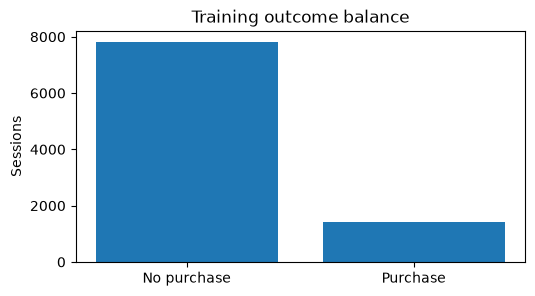

Majority-class accuracy would be 84.52%, with zero purchase sensitivity.


,median,zero %,skewness,buyer median,non-buyer median
Administrative,1.000,46.675,1.988,2.000,0.000
Administrative_Duration,8.000,47.648,5.716,54.800,0.000
Informational,0.000,78.642,4.191,0.000,0.000
Informational_Duration,0.000,80.545,7.801,0.000,0.000
ProductRelated,18.000,0.281,4.402,29.000,16.000
ProductRelated_Duration,598.250,6.175,8.228,1123.247,506.292
BounceRates,0.003,45.063,2.935,0.000,0.004
ExitRates,0.025,0.638,2.131,0.015,0.029
PageValues,0.000,77.744,6.251,17.536,0.000


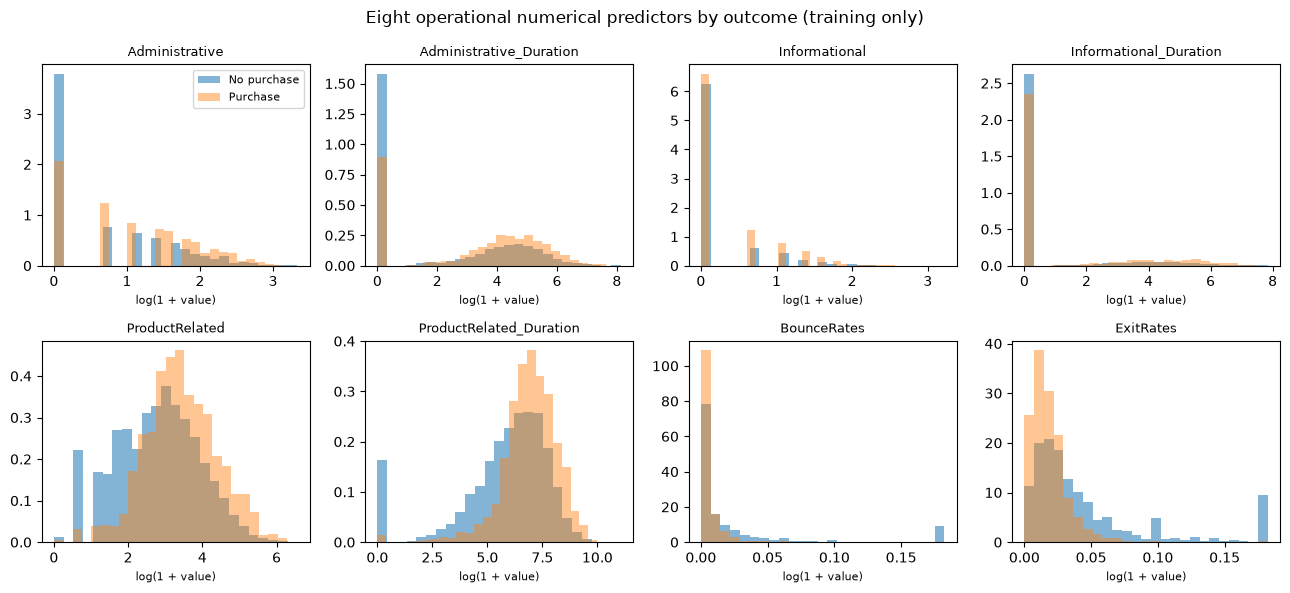

**Computed numerical finding.** The most skewed operational measure is `ProductRelated_Duration` (absolute skewness 8.23); the highest zero share is `Informational_Duration` (80.5%). This supports comparing fold-fitted transformations and zero indicators, while the CV results decide whether they improve prediction.

In [3]:
no_buy, buy = ytr.value_counts().reindex([0,1]).astype(int).values
fig, ax = plt.subplots(figsize=(5.8,3))
ax.bar(['No purchase','Purchase'],[no_buy,buy]); ax.set(title='Training outcome balance',ylabel='Sessions'); plt.show()
print(f'Majority-class accuracy would be {no_buy/len(ytr):.2%}, with zero purchase sensitivity.')
num_summary = pd.DataFrame({'median':Xtr[NUM_ALL].median(), 'zero %':100*(Xtr[NUM_ALL]==0).mean(),
    'skewness':Xtr[NUM_ALL].skew(), 'buyer median':Xtr.loc[ytr.eq(1),NUM_ALL].median(),
    'non-buyer median':Xtr.loc[ytr.eq(0),NUM_ALL].median()}).round(3)
display(num_summary)
fig, axes = plt.subplots(2,4,figsize=(13,6))
for ax,name in zip(axes.flat,NUM_SAFE):
    v=np.log1p(Xtr[name].clip(lower=0))
    ax.hist(v[ytr.eq(0)],bins=25,alpha=.55,density=True,label='No purchase')
    ax.hist(v[ytr.eq(1)],bins=25,alpha=.45,density=True,label='Purchase')
    ax.set_title(name,fontsize=9); ax.set_xlabel('log(1 + value)',fontsize=8)
axes.flat[0].legend(fontsize=8); plt.suptitle('Eight operational numerical predictors by outcome (training only)')
plt.tight_layout(); plt.show()
from IPython.display import Markdown
abs_skew=Xtr[NUM_SAFE].skew().abs().sort_values(ascending=False)
zero_rates=(Xtr[NUM_SAFE]==0).mean().sort_values(ascending=False)
display(Markdown(f"**Computed numerical finding.** The most skewed operational measure is `{abs_skew.index[0]}` (absolute skewness {abs_skew.iloc[0]:.2f}); the highest zero share is `{zero_rates.index[0]}` ({zero_rates.iloc[0]:.1%}). This supports comparing fold-fitted transformations and zero indicators, while the CV results decide whether they improve prediction."))


### Categorical EDA

**Objective and method.** Compare category frequencies and observed purchase rates for each training-only nominal predictor. Rates at rare levels are noisy and are descriptive, not evidence of a causal category effect. **Implication:** encode nominal codes with one-hot encoding inside each fold, and interpret sparse levels cautiously.

,levels,largest category %,purchase-rate range %
feature,,,
SpecialDay,6,89.596626,2.0–16.6
Month,10,27.576511,1.4–24.8
OperatingSystems,8,53.465989,10.7–25.0
Browser,13,64.420893,0.0–42.9
Region,9,38.088029,14.1–16.9
TrafficType,20,31.729209,0.0–33.3
VisitorType,3,85.541257,14.0–24.7
Weekend,2,76.954688,14.8–17.6


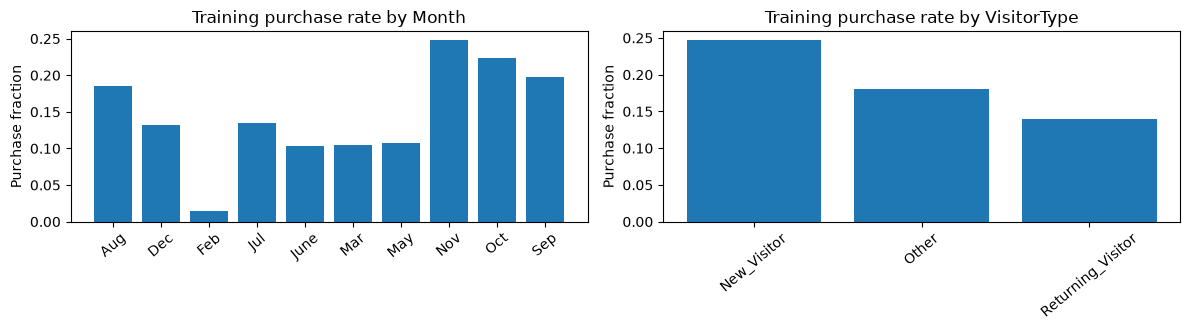

**Computed categorical finding.** `SpecialDay` has the most concentrated single level (89.6% of training sessions); `Browser` has the widest observed level purchase-rate range (42.9%). These descriptive differences motivate fold-safe one-hot encoding, while sparse level rates need cautious interpretation.

In [4]:
cat_summary=[]
for name in CAT_ALL:
    rates=pd.DataFrame({'level':Xtr[name],'purchase':ytr}).groupby('level').agg(
        sessions=('purchase','size'),purchase_rate=('purchase','mean')).sort_values('sessions',ascending=False)
    cat_summary.append({'feature':name,'levels':rates.shape[0],
        'largest category %':100*rates.sessions.max()/len(Xtr),
        'purchase-rate range %':f'{100*rates.purchase_rate.min():.1f}–{100*rates.purchase_rate.max():.1f}'})
display(pd.DataFrame(cat_summary).set_index('feature'))
fig,axs=plt.subplots(1,2,figsize=(12,3.4))
for ax,name in zip(axs,['Month','VisitorType']):
    p=pd.DataFrame({'category':Xtr[name],'purchase':ytr}).groupby('category').purchase.agg(['mean','size'])
    ax.bar(p.index,p['mean']); ax.set(title=f'Training purchase rate by {name}',ylabel='Purchase fraction')
    ax.tick_params(axis='x',rotation=40)
plt.tight_layout(); plt.show()
concentrations=pd.DataFrame(cat_summary).set_index('feature')
# Pick the category concentration maximum using the numeric summary rather than the formatted rate range.
dominant=max(CAT_ALL,key=lambda name:Xtr[name].value_counts(normalize=True).max())
rate_spread={name:pd.DataFrame({'x':Xtr[name],'y':ytr}).groupby('x').y.mean().max()-pd.DataFrame({'x':Xtr[name],'y':ytr}).groupby('x').y.mean().min() for name in CAT_ALL}
widest=max(rate_spread,key=rate_spread.get)
display(Markdown(f"**Computed categorical finding.** `{dominant}` has the most concentrated single level ({Xtr[dominant].value_counts(normalize=True).max():.1%} of training sessions); `{widest}` has the widest observed level purchase-rate range ({rate_spread[widest]:.1%}). These descriptive differences motivate fold-safe one-hot encoding, while sparse level rates need cautious interpretation."))


### EDA interpretation and next step

The computed training summaries above show the observed class balance, numeric skew/zero prevalence and categorical rate variation. We use stratification to preserve class proportions, test transforms and zero indicators through CV, and one-hot encode categories within folds. None of these associations identifies unique customers or estimates voucher response.

## 2. Pipelines and evaluation machinery

**Methodology.** Numeric imputation, optional transformations, scaling and one-hot category encoding are composed in an sklearn pipeline. For every candidate, one loop fits five fold-specific pipelines and records fold AUC and OOF probabilities from those same fits. Warnings are captured with their messages and summarized; they are not suppressed. Any fit or prediction failure is recorded in the ledger.

The first pass contains four all-17 designs. The complete bounded design list contains 29 configurations, including these diagnostics; only successful configurations explicitly registered in the Operational16 candidate set can be selected, including variants whose short labels do not contain the text `Operational16`.

In [5]:
class LogAndZeroIndicators(BaseEstimator, TransformerMixin):
    def fit(self,X,y=None):
        A=np.asarray(X,float); self.zero_columns_=np.flatnonzero((A==0).mean(axis=0)>=.50); return self
    def transform(self,X):
        A=np.asarray(X,float)
        return np.column_stack([np.log1p(np.maximum(A,0)),(A[:,self.zero_columns_]>0).astype(float)])
class ColumnSubset(BaseEstimator, TransformerMixin):
    def __init__(self,columns): self.columns=columns
    def fit(self,X,y=None): return self
    def transform(self,X): return X.loc[:,self.columns].copy()
def build(model,columns,numeric_transform='raw',poly=False):
    nums=[c for c in NUM_ALL if c in columns]; cats=[c for c in CAT_ALL if c in columns]
    numeric=[('impute',SimpleImputer(strategy='median'))]
    transforms={'log1p':FunctionTransformer(np.log1p,validate=False),
        'yeojohnson':PowerTransformer(method='yeo-johnson',standardize=False),
        'quantile':QuantileTransformer(n_quantiles=200,output_distribution='normal',random_state=SEED),
        'zeroind':LogAndZeroIndicators()}
    if numeric_transform in transforms: numeric.append(('transform',transforms[numeric_transform]))
    elif numeric_transform!='raw': raise ValueError('Unknown numeric transform: '+numeric_transform)
    if poly: numeric.append(('interactions',PolynomialFeatures(degree=2,interaction_only=True,include_bias=False)))
    numeric.append(('scale',StandardScaler()))
    pre=ColumnTransformer([('numeric',Pipeline(numeric),nums),('categorical',Pipeline([
        ('impute',SimpleImputer(strategy='most_frequent')),
        ('encode',OneHotEncoder(handle_unknown='ignore',drop='first',sparse_output=False))]),cats)],
        remainder='drop',sparse_threshold=0.0)
    return Pipeline([('subset',ColumnSubset(list(columns))),('pre',pre),('clf',clone(model))])
def confusion_rates(y_true,prob,t=.5):
    tn,fp,fn,tp=confusion_matrix(y_true,np.asarray(prob)>=t,labels=[0,1]).ravel()
    return {'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
        'sensitivity':tp/(tp+fn) if tp+fn else np.nan,
        'specificity':tn/(tn+fp) if tn+fp else np.nan}
def revenue_at(y_true,prob,t):
    r=confusion_rates(y_true,prob,t)
    r0=r['TP']+r['FN']; rm=r['TP']+.80*(r['FN']+r['TN'])
    delta=rm-r0
    return {**r,'R0_A':float(r0),'Rmodel_A':float(rm),'delta_A':float(delta),
        'relative_lift':float(delta/r0) if r0 else np.nan,'voucher_count':r['FN']+r['TN']}
MODELS={'Logistic':LogisticRegression(max_iter=3000),'Gaussian NB':GaussianNB(),
        'LDA':LinearDiscriminantAnalysis(),'QDA':QuadraticDiscriminantAnalysis()}
CONFIGS={}; RESULTS={}; LEDGER=[]
def evaluate(label,model,columns,transform='raw',poly=False,stage='candidate'):
    if label in CONFIGS: raise ValueError('Duplicate candidate label: '+label)
    pipe=build(model,columns,transform,poly); CONFIGS[label]=pipe
    oof=np.full(len(Xtr),np.nan); fold_auc=[]; warning_records=[]; failure=''
    try:
        for fold,(fit_idx,val_idx) in enumerate(FOLDS.split(Xtr,ytr),start=1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                try:
                    fitted=clone(pipe).fit(Xtr.iloc[fit_idx],ytr.iloc[fit_idx])
                    pred=fitted.predict_proba(Xtr.iloc[val_idx])[:,1]
                finally:
                    for w in caught:
                        warning_records.append({'fold':fold,'category':w.category.__name__,'message':str(w.message)[:240]})
            if not np.all(np.isfinite(pred)): raise ValueError(f'non-finite predictions in fold {fold}')
            oof[val_idx]=pred
            fold_auc.append(roc_auc_score(ytr.iloc[val_idx],pred))
        if np.isnan(oof).any(): raise ValueError('some training rows lack an OOF prediction')
        RESULTS[label]={'oof':oof,'fold_auc':np.asarray(fold_auc),'warnings':warning_records}
        row={'stage':stage,'candidate':label,'mean_fold_auc':float(np.mean(fold_auc)),
             'fold_auc_sd':float(np.std(fold_auc,ddof=1)),'status':'OK','warning_count':len(warning_records),'failure':''}
    except Exception as exc:
        failure=f'{type(exc).__name__}: {str(exc).splitlines()[0][:220]}'
        row={'stage':stage,'candidate':label,'mean_fold_auc':np.nan,'fold_auc_sd':np.nan,
             'status':'FAILED','warning_count':len(warning_records),'failure':failure}
        RESULTS[label]={'warnings':warning_records,'failure':failure}
    LEDGER.append(row)
    return row
print('Families:',', '.join(MODELS))

Families: Logistic, Gaussian NB, LDA, QDA


## 3. First pass: all 17 predictors

**Objective.** Follow the professor's instruction before changing predictor sets or model forms. **Method:** run the four default model families with technical one-hot encoding for nominal inputs; retain warnings and actual failures. These diagnostic fits are not candidates for operational selection because `PageValues` may be unavailable at decision time.

In [6]:
for name,estimator in MODELS.items():
    evaluate(f'ALL17 | {name}',estimator,ALL,stage='first pass all 17')
FIRST_PASS=pd.DataFrame(LEDGER).query("stage == 'first pass all 17'")
display(FIRST_PASS.set_index('candidate').round(4))

,stage,mean_fold_auc,fold_auc_sd,status,warning_count,failure
candidate,,,,,,
ALL17 | Logistic,first pass all 17,0.8947,0.0066,OK,3,
ALL17 | Gaussian NB,first pass all 17,0.6986,0.0753,OK,3,
ALL17 | LDA,first pass all 17,0.9005,0.0039,OK,3,
ALL17 | QDA,first pass all 17,NaN,NaN,FAILED,0,LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.


The table is generated from this runtime. A covariance warning and a fit failure are distinct outcomes: a warning means the estimator returned predictions with a numerical concern; a failure means the fold could not produce a result. The ledger preserves the actual warnings and failures from the installed library rather than presuming QDA must fail.

In [7]:
def warning_table(labels=None):
    rows=[]
    for label,result in RESULTS.items():
        if labels is not None and label not in labels: continue
        by={}
        for w in result.get('warnings',[]):
            key=(w['category'],w['message']); by[key]=by.get(key,0)+1
        for (category,message),count in by.items():
            rows.append({'candidate':label,'fold warnings':count,'warning type':category,'message':message})
    return pd.DataFrame(rows,columns=['candidate','fold warnings','warning type','message'])
first_labels=set(FIRST_PASS.candidate)
warns=warning_table(first_labels)
print('First-pass failures:')
display(FIRST_PASS.loc[FIRST_PASS.status.eq('FAILED'),['candidate','failure']])
print('First-pass warning details (repeated identical messages are grouped):')
display(warns)

First-pass failures:


,candidate,failure
3,ALL17 | QDA,LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.


First-pass warning details (repeated identical messages are grouped):


,candidate,fold warnings,warning type,message
0,ALL17 | Logistic,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
1,ALL17 | Logistic,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
2,ALL17 | Gaussian NB,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
3,ALL17 | Gaussian NB,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
4,ALL17 | LDA,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
5,ALL17 | LDA,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros


## 4. PageValues timing and operational baseline

**Objective.** Compare a training-only first-pass result with and without `PageValues`, then define the operational predictor set. **Interpretation:** an AUC difference is an association, not proof of leakage. The substantive concern is that this Google Analytics value may depend on completed-session information and may not exist when a voucher decision must be made. The 16 operational predictors therefore exclude it.

In [8]:
first_log=RESULTS.get('ALL17 | Logistic',{})
page_row=evaluate('Operational16 | Logistic raw',MODELS['Logistic'],SAFE,stage='operational raw baseline')
if first_log.get('fold_auc') is not None and page_row['status']=='OK':
    print(f"Logistic mean fold AUC with PageValues: {np.mean(first_log['fold_auc']):.4f}")
    print(f"Logistic mean fold AUC without PageValues: {page_row['mean_fold_auc']:.4f}")
    print(f"Difference (with minus without): {np.mean(first_log['fold_auc'])-page_row['mean_fold_auc']:+.4f}")
display(pd.crosstab(Xtr['PageValues'].gt(0),ytr,normalize='columns').rename(
    index={False:'PageValues = 0',True:'PageValues > 0'},columns={0:'Non-buyers',1:'Buyers'}).round(3))
print('Operational policy models exclude PageValues on timing/availability grounds.')

Logistic mean fold AUC with PageValues: 0.8947
Logistic mean fold AUC without PageValues: 0.7541
Difference (with minus without): +0.1406


Revenue,Non-buyers,Buyers
PageValues,,
PageValues = 0,0.886,0.182
PageValues > 0,0.114,0.818


Operational policy models exclude PageValues on timing/availability grounds.


## 5. Operational16 raw baselines and covariance repair

**Methodology.** Evaluate the remaining three unmodified Operational16 model families on the same five folds, alongside the Logistic raw baseline already fit during the `PageValues` comparison. Attempt regularised QDA as a separately labelled numerical repair after the unmodified QDA fit. This completes the raw operational comparison; no transformation or tuning is introduced until the assumption diagnostics below have been reviewed.


In [9]:
BASELINE_LABELS={}
for name,estimator in MODELS.items():
    label=f'Operational16 | {name} raw'
    row=page_row if name=='Logistic' else evaluate(label,estimator,SAFE,stage='operational raw baseline')
    if row['status']=='OK': BASELINE_LABELS[name]=label
# A separate covariance regularisation repair follows the unmodified operational QDA attempt.
repair='Operational16 | QDA regularised 0.05'
repair_row=evaluate(repair,QuadraticDiscriminantAnalysis(reg_param=.05),SAFE,stage='QDA numerical repair')
if 'QDA' not in BASELINE_LABELS and repair_row['status']=='OK':
    BASELINE_LABELS['QDA (regularised)']=repair


### Operational raw baseline comparison

**Objective and method.** Compare the four original model families on the same Operational16 folds. Report mean fold AUC, pooled OOF AUC, Brier score, and sensitivity/specificity at 0.50, alongside OOF ROC curves and confusion matrices. AUC measures ranking; thresholded rates describe only the 0.50 operating point.


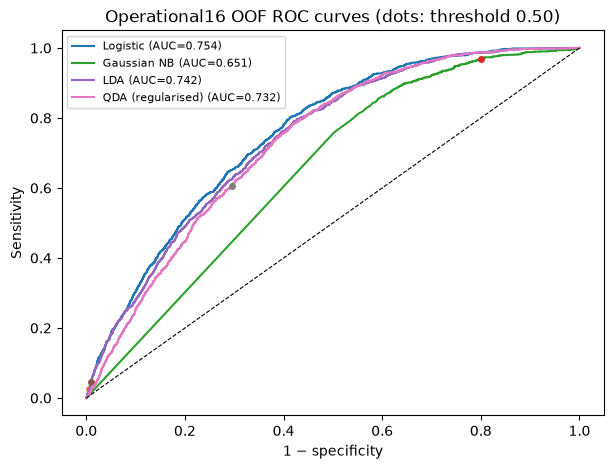

,candidate,mean fold AUC,pooled OOF AUC,Brier,sensitivity @ .5,specificity @ .5,TP,FP,FN,TN
family,,,,,,,,,,
Logistic,Operational16 | Logistic raw,0.7541,0.7540,0.1174,0.0252,0.9940,36,47,1395,7769
Gaussian NB,Operational16 | Gaussian NB raw,0.6606,0.6510,0.6792,0.9693,0.1997,1387,6255,44,1561
LDA,Operational16 | LDA raw,0.7424,0.7422,0.1194,0.0454,0.9900,65,78,1366,7738
QDA (regularised),Operational16 | QDA regularised 0.05,0.7323,0.7319,0.2203,0.6052,0.7051,866,2305,565,5511


Logistic confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,7769,47
Actual 1,1395,36


Gaussian NB confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,1561,6255
Actual 1,44,1387


LDA confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,7738,78
Actual 1,1366,65


QDA (regularised) confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,5511,2305
Actual 1,565,866


In [10]:
baseline_rows=[]
fig,ax=plt.subplots(figsize=(7,5))
for family,label in BASELINE_LABELS.items():
    if label not in RESULTS or 'oof' not in RESULTS[label]: continue
    prob=RESULTS[label]['oof']; rates=confusion_rates(ytr,prob,.5)
    baseline_rows.append({'family':family,'candidate':label,
        'mean fold AUC':np.mean(RESULTS[label]['fold_auc']),'pooled OOF AUC':roc_auc_score(ytr,prob),
        'Brier':brier_score_loss(ytr,prob),'sensitivity @ .5':rates['sensitivity'],
        'specificity @ .5':rates['specificity'],**{k:rates[k] for k in ['TP','FP','FN','TN']}})
    fpr,tpr,_=roc_curve(ytr,prob); ax.plot(fpr,tpr,label=f'{family} (AUC={roc_auc_score(ytr,prob):.3f})')
    ax.plot(1-rates['specificity'],rates['sensitivity'],'o',ms=4)
ax.plot([0,1],[0,1],'k--',lw=.8); ax.set(xlabel='1 − specificity',ylabel='Sensitivity',title='Operational16 OOF ROC curves (dots: threshold 0.50)')
ax.legend(fontsize=8); plt.show()
BASELINES=pd.DataFrame(baseline_rows).set_index('family'); display(BASELINES.round(4))
for row in baseline_rows:
    print(f"{row['family']} confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):")
    display(pd.DataFrame([[row['TN'],row['FP']],[row['FN'],row['TP']]],index=['Actual 0','Actual 1'],columns=['Predicted 0','Predicted 1']))


**Training-only diagnostics.** Numerical skew and within-class dependence are checked to explain why alternatives were considered, not to claim assumptions are fully satisfied. Large skew supports testing log/power transforms; correlated predictors challenge Gaussian Naive Bayes independence and may affect covariance estimates in discriminant analysis. The CV comparison, not the diagnostic alone, determines whether a modification is useful.

### Assumption diagnostics before modifications

**Objective and method.** Use training-only descriptive checks to explain the planned modifications: Q–Q plots for representative numerical predictors within each class (normality), class-specific numerical covariance summaries (shared-covariance assumption), correlations/condition number (independence and multicollinearity), and binned empirical logits for two predictors (linearity of log-odds). These checks are diagnostics, not formal proof of estimator validity. The full design also includes nominal categories, so numeric-only covariance summaries cannot certify multivariate normality of the encoded full feature space.


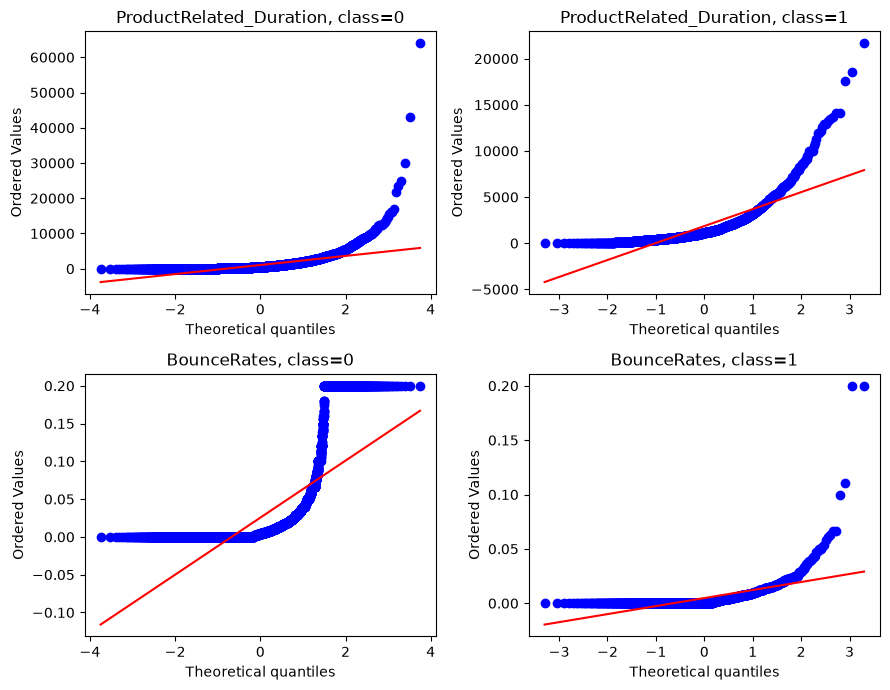

,trace,largest eigenvalue,smallest eigenvalue,condition number
class,,,,
0,3366246.229,3323621.275,0.0,1.564269e+10
1,4957046.204,4894291.732,0.0,1.107012e+11


,mean_x,n,p,empirical_logit
bin,,,,
"(-0.001, 34.5]",7.266,926,0.028,-3.526
"(34.5, 126.533]",77.631,924,0.050,-2.939
"(126.533, 244.0]",181.967,925,0.058,-2.772
"(244.0, 398.98]",316.863,924,0.120,-1.987
"(398.98, 598.25]",495.895,925,0.173,-1.562
"(598.25, 850.283]",718.777,924,0.192,-1.438
"(850.283, 1227.871]",1028.742,925,0.219,-1.267
"(1227.871, 1775.135]",1475.628,924,0.189,-1.452
"(1775.135, 2861.087]",2237.861,925,0.229,-1.211


,mean_x,n,p,empirical_logit
bin,,,,
"(-0.001, 0.00741]",0.004,937,0.293,-0.877
"(0.00741, 0.012]",0.010,913,0.256,-1.064
"(0.012, 0.0161]",0.014,924,0.251,-1.091
"(0.0161, 0.0205]",0.018,925,0.210,-1.325
"(0.0205, 0.0251]",0.023,925,0.194,-1.425
"(0.0251, 0.0325]",0.029,924,0.148,-1.745
"(0.0325, 0.0417]",0.037,946,0.106,-2.131
"(0.0417, 0.0591]",0.049,903,0.053,-2.870
"(0.0591, 0.1]",0.080,1008,0.028,-3.538


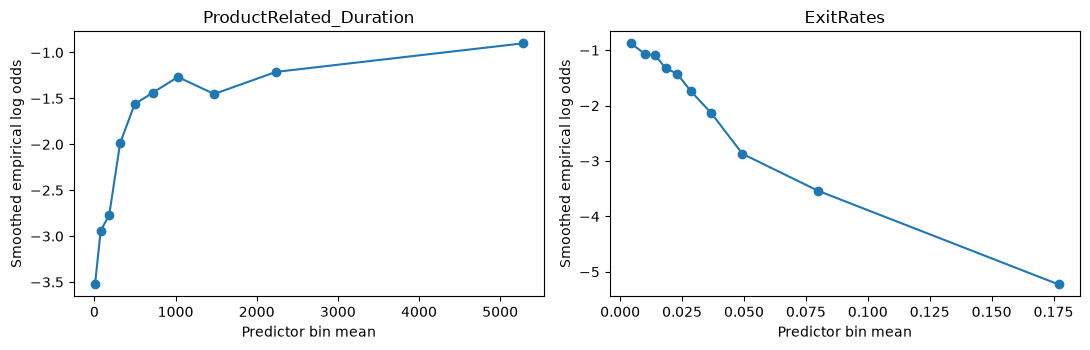

In [11]:
from scipy.stats import probplot
fig,axes=plt.subplots(2,2,figsize=(9,7))
for row,(feature,outcome) in enumerate([('ProductRelated_Duration',0),('ProductRelated_Duration',1),('BounceRates',0),('BounceRates',1)]):
    values=Xtr.loc[ytr.eq(outcome),feature].to_numpy()
    probplot(values,dist='norm',plot=axes[row//2,row%2])
    axes[row//2,row%2].set_title(f'{feature}, class={outcome}')
plt.tight_layout(); plt.show()

class_cov=[]
for outcome in (0,1):
    cov=Xtr.loc[ytr.eq(outcome),NUM_SAFE].cov().to_numpy()
    eig=np.linalg.eigvalsh(cov)
    class_cov.append({'class':outcome,'trace':np.trace(cov),'largest eigenvalue':eig.max(),
                      'smallest eigenvalue':eig.min(),'condition number':eig.max()/max(eig.min(),1e-15)})
display(pd.DataFrame(class_cov).set_index('class').round(3))

fig,axes=plt.subplots(1,2,figsize=(11,3.6))
for ax,feature in zip(axes,['ProductRelated_Duration','ExitRates']):
    bins=pd.qcut(Xtr[feature],q=10,duplicates='drop')
    tab=pd.DataFrame({'bin':bins,'y':ytr,'x':Xtr[feature]}).groupby('bin',observed=True).agg(
        mean_x=('x','mean'),n=('y','size'),p=('y','mean'))
    tab['empirical_logit']=np.log((tab.p*tab.n+0.5)/((1-tab.p)*tab.n+0.5))
    display(tab.round(3))
    ax.plot(tab.mean_x,tab.empirical_logit,'o-')
    ax.set(title=feature,xlabel='Predictor bin mean',ylabel='Smoothed empirical log odds')
plt.tight_layout(); plt.show()


In [12]:
assumption_rows=[]
for col in NUM_SAFE:
    for outcome in (0,1):
        arr=Xtr.loc[ytr.eq(outcome),col].to_numpy()
        assumption_rows.append({'variable':col,'class':outcome,'skew':stats.skew(arr),'zero %':100*np.mean(arr==0)})
ASSUMPTIONS=pd.DataFrame(assumption_rows)
display(ASSUMPTIONS.pivot(index='variable',columns='class',values=['skew','zero %']).round(2))
abs_skew=Xtr[NUM_SAFE].skew().abs().sort_values(ascending=False)
# Pairwise dependence and a scale-normalized covariance comparison use the continuous numeric predictors only.
corr_summaries={}
for outcome in (0,1):
    corr=Xtr.loc[ytr.eq(outcome),NUM_SAFE].corr()
    pairs=corr.abs().where(~np.eye(len(corr),dtype=bool)).stack().sort_values(ascending=False)
    corr_summaries[outcome]=(pairs.index[0],float(pairs.iloc[0]))
    print(f'Class {outcome}: largest absolute numeric correlation {pairs.index[0]} = {pairs.iloc[0]:.3f}')
num_corr=Xtr[NUM_SAFE].corr().to_numpy()
condition=np.linalg.cond(num_corr)
cov0=Xtr.loc[ytr.eq(0),NUM_SAFE].cov().to_numpy(); cov1=Xtr.loc[ytr.eq(1),NUM_SAFE].cov().to_numpy()
pooled_std=Xtr[NUM_SAFE].std().to_numpy(); scale=np.diag(1/pooled_std)
scaled_cov_difference=np.linalg.norm(scale@(cov1-cov0)@scale,ord='fro')
print(f'Scaled numeric correlation-matrix condition number: {condition:.2f}')
print(f'Scale-normalized Frobenius difference between class covariance matrices: {scaled_cov_difference:.3f}')
display(Markdown(f"""
**Computed assumption findings.** `{abs_skew.index[0]}` has the largest absolute training skewness ({abs_skew.iloc[0]:.2f}); the strongest within-class numeric correlation is `{corr_summaries[0][0]}` for non-buyers ({corr_summaries[0][1]:.2f}) and `{corr_summaries[1][0]}` for buyers ({corr_summaries[1][1]:.2f}). The scale-normalized covariance difference is {scaled_cov_difference:.2f}; the raw covariance condition numbers above are sensitive to measurement scales, so the normalized comparison is more interpretable. The empirical-logit and Q–Q plots assess shape visually. These numerical-only diagnostics suggest departures from normality, independence and equal covariance, but cannot establish assumptions for the full mixed, one-hot encoded predictor space. We therefore test a small set of transforms, interactions and regularisation variants inside CV after completing this diagnostic stage.
"""))


skew       zero %       
class                        0     1      0      1
variable                                          
Administrative            2.16  1.37  50.47  25.93
Administrative_Duration   6.29  3.81  51.37  27.32
BounceRates               2.65  8.72  43.16  55.49
ExitRates                 1.92  3.62   0.38   2.03
Informational             4.62  2.80  80.64  67.71
Informational_Duration    8.69  4.87  82.43  70.23
ProductRelated            4.80  3.25   0.31   0.14
ProductRelated_Duration  10.08  3.09   7.20   0.56

Class 0: largest absolute numeric correlation ('ExitRates', 'BounceRates') = 0.914
Class 1: largest absolute numeric correlation ('ProductRelated', 'ProductRelated_Duration') = 0.899
Scaled numeric correlation-matrix condition number: 42.22
Scale-normalized Frobenius difference between class covariance matrices: 2.851



**Computed assumption findings.** `ProductRelated_Duration` has the largest absolute training skewness (8.23); the strongest within-class numeric correlation is `('ExitRates', 'BounceRates')` for non-buyers (0.91) and `('ProductRelated', 'ProductRelated_Duration')` for buyers (0.90). The scale-normalized covariance difference is 2.85; the raw covariance condition numbers above are sensitive to measurement scales, so the normalized comparison is more interpretable. The empirical-logit and Q–Q plots assess shape visually. These numerical-only diagnostics suggest departures from normality, independence and equal covariance, but cannot establish assumptions for the full mixed, one-hot encoded predictor space. We therefore test a small set of transforms, interactions and regularisation variants inside CV after completing this diagnostic stage.


### Bounded CV-guided improvements

**Methodology.** After the first-pass and assumption diagnostics, compare 12 log/power/quantile/zero-indicator variants across Logistic Regression, Gaussian Naive Bayes and LDA, three interaction/subset alternatives, five model-specific tuning variants, and one QDA regularisation repair. Including four all-17 first-pass fits and four raw Operational16 families gives exactly 29 recorded designs. Failed designs remain visible in the ledger. All transformations and encoders are fitted within each training fold.


In [13]:
CANDIDATES={name:label for name,label in BASELINE_LABELS.items()}
if repair_row['status']=='OK': CANDIDATES['QDA (regularised)']=repair
for transform in ['log1p','yeojohnson','quantile','zeroind']:
    for name in ['Logistic','Gaussian NB','LDA']:
        label=f'{name} | {transform}'
        row=evaluate(label,MODELS[name],SAFE,transform,stage='transformation')
        if row['status']=='OK': CANDIDATES[label]=label
five=['ExitRates','ProductRelated_Duration','Month','TrafficType','VisitorType']
for label,model,columns,transform,poly in [
    ('Logistic | raw interactions',MODELS['Logistic'],SAFE,'raw',True),
    ('Logistic | five original predictors',MODELS['Logistic'],five,'raw',False),
    ('LDA | yeojohnson interactions',MODELS['LDA'],SAFE,'yeojohnson',True)]:
    row=evaluate(label,model,columns,transform,poly,stage='nonlinearity or subset')
    if row['status']=='OK': CANDIDATES[label]=label
for label,model,transform in [
    ('Logistic | L2 C=0.1',LogisticRegression(C=.1,max_iter=3000),'raw'),
    ('Logistic | L2 C=10',LogisticRegression(C=10,max_iter=3000),'raw'),
    ('Gaussian NB | smoother',GaussianNB(var_smoothing=1e-5),'raw'),
    ('LDA | shrinkage',LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto'),'raw'),
    ('QDA | regularised 0.01',QuadraticDiscriminantAnalysis(reg_param=.01),'raw')]:
    row=evaluate(label,model,SAFE,transform,stage='model-specific tuning')
    if row['status']=='OK': CANDIDATES[label]=label
LED=pd.DataFrame(LEDGER)
print(f'Candidate designs recorded: {len(LED)} (expected 29); successful registered operational candidates: {len(CANDIDATES)}')
display(LED[['stage','candidate','mean_fold_auc','fold_auc_sd','status','warning_count','failure']].round(4))
print('Warnings recorded across all attempted candidate fits (identical messages grouped):')
display(warning_table())


Candidate designs recorded: 29 (expected 29); successful registered operational candidates: 24


,stage,candidate,mean_fold_auc,fold_auc_sd,status,warning_count,failure
0,first pass all 17,ALL17 | Logistic,0.8947,0.0066,OK,3,
1,first pass all 17,ALL17 | Gaussian NB,0.6986,0.0753,OK,3,
2,first pass all 17,ALL17 | LDA,0.9005,0.0039,OK,3,
3,first pass all 17,ALL17 | QDA,NaN,NaN,FAILED,0,LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.
4,operational raw baseline,Operational16 | Logistic raw,0.7541,0.0217,OK,3,
5,operational raw baseline,Operational16 | Gaussian NB raw,0.6606,0.0513,OK,3,
6,operational raw baseline,Operational16 | LDA raw,0.7424,0.0201,OK,3,
7,operational raw baseline,Operational16 | QDA raw,NaN,NaN,FAILED,0,LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.
8,QDA numerical repair,Operational16 | QDA regularised 0.05,0.7323,0.0187,OK,3,
9,transformation,Logistic | log1p,0.7610,0.0215,OK,3,


Warnings recorded across all attempted candidate fits (identical messages grouped):


,candidate,fold warnings,warning type,message
0,ALL17 | Logistic,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
1,ALL17 | Logistic,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
2,ALL17 | Gaussian NB,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
3,ALL17 | Gaussian NB,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
4,ALL17 | LDA,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
5,ALL17 | LDA,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
6,Operational16 | Logistic raw,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
7,Operational16 | Logistic raw,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
8,Operational16 | Gaussian NB raw,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
9,Operational16 | Gaussian NB raw,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros


**Warning interpretation.** The one-hot encoder is fitted on each fold's training rows and uses `handle_unknown='ignore'`. A category appearing only in a validation fold is represented by an all-zero encoding for that feature; the associated unknown-category warning is expected for rare levels and is handled by the declared pipeline. It is not a fit failure or evidence that validation data influenced training. Other warnings and complete failure messages remain visible in the grouped table above.

## 6. Candidate comparison and OOF revenue threshold selection

**Objective.** Maximise the simulated revenue formula on training OOF predictions for every successful candidate in the explicit Operational16 registry, irrespective of the candidate label text. For each candidate, sort the distinct OOF probabilities and use cumulative counts to scan score cutpoints in `O(n log n)`. The scan uses cumulative counts, includes 0, 0.80, 1 and the cutoff immediately above the maximum score, and represents every distinct score assignment. It does not restrict the optimizer to voucher only a selected fraction of sessions.

**Interpretation.** Under A1, an optimum that issues vouchers to most or nearly all sessions can occur because the assumed conversion is guaranteed. That outcome is a consequence of the hypothetical assumption, not evidence that real vouchers cause conversion.

In [14]:
def optimal_revenue_threshold(y_true,prob):
    y=np.asarray(y_true,dtype=int); p=np.asarray(prob,dtype=float)
    order=np.argsort(p,kind='mergesort'); ps=p[order]; ys=y[order]
    distinct=np.unique(ps)
    candidates=np.unique(np.r_[0.0,THEORY_THRESHOLD,1.0,distinct,
        np.nextafter(float(ps.max()),np.inf)])
    # One binary search per cutoff and cumulative counts give all confusion outcomes in O(n log n).
    starts=np.searchsorted(ps,candidates,side='left')
    cum_buyers=np.r_[0,np.cumsum(ys)]
    cum_nonbuyers=np.r_[0,np.cumsum(1-ys)]
    total_buyers=int(ys.sum()); total_nonbuyers=len(ys)-total_buyers
    best=None
    for t,start in zip(candidates,starts):
        tp=total_buyers-int(cum_buyers[start]); fp=total_nonbuyers-int(cum_nonbuyers[start])
        fn=total_buyers-tp; tn=total_nonbuyers-fp
        r0=tp+fn; rm=tp+.80*(fn+tn)
        score5=5*tp+4*(fn+tn)  # exactly 5 x model revenue in units of A; integer score avoids float tie errors
        key=(score5,-abs(float(t)-THEORY_THRESHOLD),-float(t))
        if best is None or key>best[0]:
            best=(key,float(t),{'score5':int(score5),'TP':tp,'FP':fp,'FN':fn,'TN':tn,'R0_A':float(r0),
                'Rmodel_A':float(rm),'delta_A':float(rm-r0),
                'relative_lift':float((rm-r0)/r0) if r0 else np.nan,
                'voucher_count':fn+tn,'sensitivity':tp/r0 if r0 else np.nan,
                'specificity':tn/total_nonbuyers if total_nonbuyers else np.nan})
    return best[1],best[2]

selection_rows=[]
for label in CANDIDATES.values():
    result=RESULTS[label]
    if result.get('failure') or 'oof' not in result: continue
    p=result['oof']
    threshold,rev=optimal_revenue_threshold(ytr,p)
    selection_rows.append({'candidate':label,'mean_fold_auc':float(np.mean(result['fold_auc'])),
        'pooled_oof_auc':roc_auc_score(ytr,p),'threshold':threshold,**rev})
SELECTION=pd.DataFrame(selection_rows).sort_values(
    ['score5','mean_fold_auc','candidate'],ascending=[False,False,True],kind='mergesort').reset_index(drop=True)
if SELECTION.empty:
    raise RuntimeError('No registered operational candidate completed five-fold OOF prediction.')
WINNER=str(SELECTION.iloc[0].candidate); T_OPT=float(SELECTION.iloc[0].threshold)
P_TRAIN=RESULTS[WINNER]['oof']; CV_AUC=float(SELECTION.iloc[0].mean_fold_auc)
print('Selection order: exact OOF revenue score, then mean fold AUC, then candidate label.')
display(SELECTION.head(12).round(4))
print(f'Winner: {WINNER} | mean fold AUC={CV_AUC:.4f} | pooled OOF AUC={roc_auc_score(ytr,P_TRAIN):.4f} | threshold={T_OPT:.6f}')
print('Complete candidate evaluation ledger:'); display(LED)


def family_of(label):
    if 'QDA' in label: return 'QDA'
    if 'Gaussian NB' in label: return 'Gaussian NB'
    if 'LDA' in label: return 'LDA'
    return 'Logistic'
AUC_ORDER=SELECTION.sort_values(['mean_fold_auc','candidate'],ascending=[False,True])
AUC_WINNER=str(AUC_ORDER.iloc[0].candidate)
family_improvements=[]
for family,raw_label in BASELINE_LABELS.items():
    canonical=family_of(family+' '+raw_label)
    family_rows=SELECTION.loc[SELECTION.candidate.map(family_of).eq(canonical)]
    if family_rows.empty: continue
    raw_auc=float(RESULTS[raw_label]['fold_auc'].mean()) if raw_label in RESULTS and 'fold_auc' in RESULTS[raw_label] else np.nan
    best_family=family_rows.sort_values(['mean_fold_auc','candidate'],ascending=[False,True]).iloc[0]
    family_improvements.append({'family':canonical,'reference specification':raw_label,
        'reference mean fold AUC':raw_auc,'best CV specification':best_family.candidate,
        'best mean fold AUC':float(best_family.mean_fold_auc),
        'AUC change vs reference':float(best_family.mean_fold_auc-raw_auc) if np.isfinite(raw_auc) else np.nan})
FAMILY_AUC=pd.DataFrame(family_improvements).drop_duplicates('family').set_index('family')
print('Discrimination improvement by family; AUC and revenue are distinct objectives:')
display(FAMILY_AUC.round(4))
print(f'AUC winner: {AUC_WINNER} (mean fold AUC {AUC_ORDER.iloc[0].mean_fold_auc:.4f}); revenue winner: {WINNER} (OOF revenue {SELECTION.iloc[0].Rmodel_A:.1f}A at threshold {T_OPT:.4f}).')
if AUC_WINNER != WINNER:
    print('The selected revenue policy differs from the highest-AUC model because ranking and thresholded simulated revenue optimize different quantities.')

if 'QDA' not in BASELINE_LABELS and 'QDA (regularised)' in BASELINE_LABELS:
    print('QDA reference in this table is the separately labelled regularised model because the unregularised operational QDA fit failed; the raw failure remains in the ledger.')

log_reference=SELECTION.loc[SELECTION.candidate.eq('Logistic | log1p')]
if not log_reference.empty:
    log_revenue=float(log_reference.iloc[0].Rmodel_A)
    revenue_margin=float(SELECTION.iloc[0].Rmodel_A-log_revenue)
    print(f"Selected OOF revenue minus Logistic | log1p OOF revenue: {revenue_margin:+.1f}A (selected={SELECTION.iloc[0].Rmodel_A:.1f}A; log1p={log_revenue:.1f}A).")
    print('A very small OOF revenue margin, even with an AUC tie-break, does not establish robust superiority; both model and cutoff were selected on these same OOF predictions.')


Selection order: exact OOF revenue score, then mean fold AUC, then candidate label.


,candidate,mean_fold_auc,pooled_oof_auc,threshold,score5,TP,FP,FN,TN,R0_A,Rmodel_A,delta_A,relative_lift,voucher_count,sensitivity,specificity
0,Logistic | quantile,0.7615,0.7610,0.8360,36989,1,0,1430,7816,1431.0,7397.8,5966.8,4.1697,9246,0.0007,1.0
1,Logistic | log1p,0.7610,0.7609,0.6674,36989,1,0,1430,7816,1431.0,7397.8,5966.8,4.1697,9246,0.0007,1.0
2,Logistic | yeojohnson,0.7621,0.7619,0.8019,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
3,LDA | yeojohnson interactions,0.7615,0.7615,0.8811,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
4,Logistic | zeroind,0.7612,0.7609,0.8000,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
5,Logistic | raw interactions,0.7574,0.7573,1.0000,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
6,LDA | yeojohnson,0.7549,0.7546,0.8107,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
7,Operational16 | Logistic raw,0.7541,0.7540,0.9948,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
8,Logistic | L2 C=0.1,0.7535,0.7533,0.9930,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0
9,Logistic | L2 C=10,0.7533,0.7532,0.9950,36988,0,0,1431,7816,1431.0,7397.6,5966.6,4.1695,9247,0.0000,1.0


Winner: Logistic | quantile | mean fold AUC=0.7615 | pooled OOF AUC=0.7610 | threshold=0.835952
Complete candidate evaluation ledger:


,stage,candidate,mean_fold_auc,fold_auc_sd,status,warning_count,failure
0,first pass all 17,ALL17 | Logistic,0.894718,0.006614,OK,3,
1,first pass all 17,ALL17 | Gaussian NB,0.698642,0.075307,OK,3,
2,first pass all 17,ALL17 | LDA,0.900502,0.003933,OK,3,
3,first pass all 17,ALL17 | QDA,NaN,NaN,FAILED,0,LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.
4,operational raw baseline,Operational16 | Logistic raw,0.754075,0.021676,OK,3,
5,operational raw baseline,Operational16 | Gaussian NB raw,0.660601,0.051285,OK,3,
6,operational raw baseline,Operational16 | LDA raw,0.742414,0.020139,OK,3,
7,operational raw baseline,Operational16 | QDA raw,NaN,NaN,FAILED,0,LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.
8,QDA numerical repair,Operational16 | QDA regularised 0.05,0.732326,0.018677,OK,3,
9,transformation,Logistic | log1p,0.761048,0.021453,OK,3,


Discrimination improvement by family; AUC and revenue are distinct objectives:


,reference specification,reference mean fold AUC,best CV specification,best mean fold AUC,AUC change vs reference
family,,,,,
Logistic,Operational16 | Logistic raw,0.7541,Logistic | yeojohnson,0.7621,0.0080
Gaussian NB,Operational16 | Gaussian NB raw,0.6606,Gaussian NB | smoother,0.7061,0.0455
LDA,Operational16 | LDA raw,0.7424,LDA | yeojohnson interactions,0.7615,0.0191
QDA,Operational16 | QDA regularised 0.05,0.7323,Operational16 | QDA regularised 0.05,0.7323,0.0000


AUC winner: Logistic | yeojohnson (mean fold AUC 0.7621); revenue winner: Logistic | quantile (OOF revenue 7397.8A at threshold 0.8360).
The selected revenue policy differs from the highest-AUC model because ranking and thresholded simulated revenue optimize different quantities.
QDA reference in this table is the separately labelled regularised model because the unregularised operational QDA fit failed; the raw failure remains in the ledger.
Selected OOF revenue minus Logistic | log1p OOF revenue: +0.0A (selected=7397.8A; log1p=7397.8A).
A very small OOF revenue margin, even with an AUC tie-break, does not establish robust superiority; both model and cutoff were selected on these same OOF predictions.


### Dynamic results: model choice and assumptions

The next display is generated from the computed candidate table so its statements stay consistent when the notebook runs under the current library versions. Mean fold AUC summarizes fold discrimination; pooled OOF AUC pools the held-out fold predictions. The selected revenue and threshold are optimized on these same OOF predictions and therefore carry selection optimism.

In [15]:
TOP=SELECTION.iloc[0]
second=SELECTION.iloc[1] if len(SELECTION)>1 else TOP
FIRST_OK=FIRST_PASS.loc[FIRST_PASS.status.eq('OK'),['candidate','mean_fold_auc']].sort_values('mean_fold_auc',ascending=False)
first_text='; '.join(f"{r.candidate}: AUC {r.mean_fold_auc:.3f}" for r in FIRST_OK.itertuples()) or 'no all-17 model completed successfully'
display(Markdown(f"""
**Computed results.** The all-17 first pass produced: {first_text}. The highest-ranked operational candidate by OOF simulated revenue is **{WINNER}**, with an empirical threshold of **{T_OPT:.4f}**, mean five-fold AUC **{CV_AUC:.4f}**, and pooled OOF AUC **{roc_auc_score(ytr,P_TRAIN):.4f}**. The runner-up revenue was **{second.Rmodel_A:.1f}A**, versus **{TOP.Rmodel_A:.1f}A** for the selected candidate.

**Implication.** This winner is selected for the stated simulated revenue objective; AUC is reported as a separate measure of discrimination. Since the same OOF predictions select both model and threshold, these training figures are not an unbiased final performance estimate. The historical test partition supplies a fixed-threshold comparison, with the caveat that this partition was previously viewed.
"""))


**Computed results.** The all-17 first pass produced: ALL17 | LDA: AUC 0.901; ALL17 | Logistic: AUC 0.895; ALL17 | Gaussian NB: AUC 0.699. The highest-ranked operational candidate by OOF simulated revenue is **Logistic | quantile**, with an empirical threshold of **0.8360**, mean five-fold AUC **0.7615**, and pooled OOF AUC **0.7610**. The runner-up revenue was **7397.8A**, versus **7397.8A** for the selected candidate.

**Implication.** This winner is selected for the stated simulated revenue objective; AUC is reported as a separate measure of discrimination. Since the same OOF predictions select both model and threshold, these training figures are not an unbiased final performance estimate. The historical test partition supplies a fixed-threshold comparison, with the caveat that this partition was previously viewed.


## 7. Threshold extension: sensitivity, specificity, revenue and calibration

**Objective.** Show how the selected model's operating characteristics change with the cutoff and compare 0.50, the theoretically calibrated 0.80 threshold, and the OOF revenue-optimal threshold. These are threshold settings within the same model-guided policy, not extra business scenarios. The no-voucher baseline remains fixed.

**Method.** Plot sensitivity, specificity, simulated revenue, and weighted opportunity cost `0.80 FP + 0.20 FN`. Also compare Brier score and a reliability curve to assess whether probabilities align with observed purchase frequencies; calibration diagnostics help interpret deviations from the theoretical 0.80 rule.

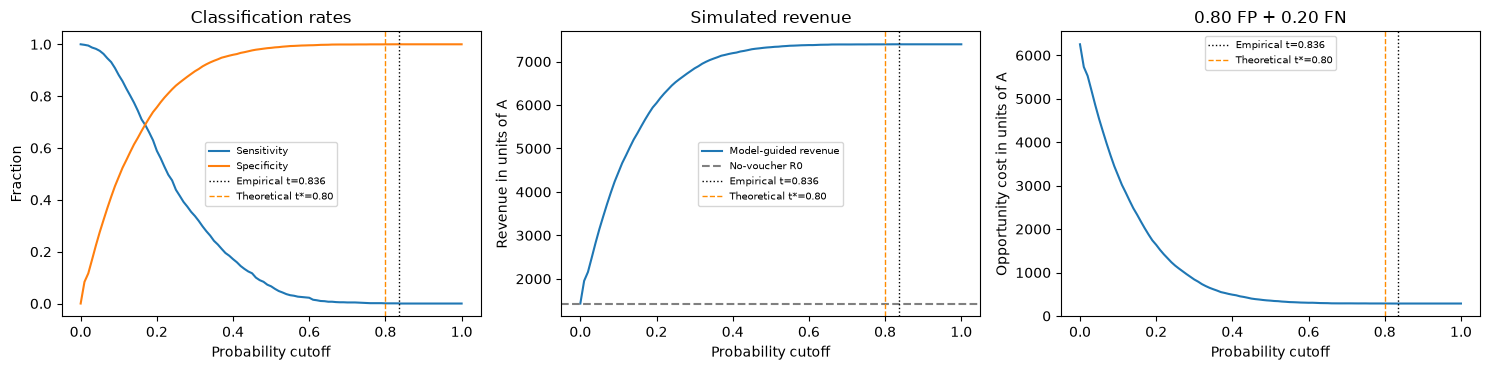

,threshold,TN,FP,FN,TP,sensitivity,specificity,R0_A,Rmodel_A,delta_A,relative_lift,voucher_count
setting,,,,,,,,,,,,
default,0.500,7709,107,1336,95,0.0664,0.9863,1431.0,7331.0,5900.0,4.1230,9045
theoretical,0.800,7815,1,1430,1,0.0007,0.9999,1431.0,7397.0,5966.0,4.1691,9245
empirical optimum,0.836,7816,0,1430,1,0.0007,1.0000,1431.0,7397.8,5966.8,4.1697,9246


Training OOF Brier score: 0.11649


In [16]:
threshold_grid=np.unique(np.r_[np.linspace(0,1,101),THEORY_THRESHOLD,T_OPT])
threshold_rows=[{'threshold':float(t),**revenue_at(ytr,P_TRAIN,float(t)),
    'weighted_opportunity_cost_A':.80*confusion_rates(ytr,P_TRAIN,float(t))['FP']+
                                    .20*confusion_rates(ytr,P_TRAIN,float(t))['FN']}
    for t in threshold_grid]
THRESHOLD_CURVE=pd.DataFrame(threshold_rows)
fig,axes=plt.subplots(1,3,figsize=(15,3.8))
axes[0].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity')
axes[0].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity')
axes[0].set(xlabel='Probability cutoff',ylabel='Fraction',title='Classification rates')
axes[1].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.Rmodel_A,label='Model-guided revenue')
axes[1].axhline(THRESHOLD_CURVE.iloc[0].R0_A,color='grey',ls='--',label='No-voucher R0')
axes[1].set(xlabel='Probability cutoff',ylabel='Revenue in units of A',title='Simulated revenue')
axes[2].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.weighted_opportunity_cost_A)
axes[2].set(xlabel='Probability cutoff',ylabel='Opportunity cost in units of A',title='0.80 FP + 0.20 FN')
for ax in axes:
    ax.axvline(T_OPT,color='black',ls=':',lw=1,label=f'Empirical t={T_OPT:.3f}')
    ax.axvline(THEORY_THRESHOLD,color='darkorange',ls='--',lw=1,label=f'Theoretical t*={THEORY_THRESHOLD:.2f}')
    ax.legend(fontsize=7,loc='best')
plt.tight_layout(); plt.show()
threshold_comparison=[]
for label,t in [('default',.5),('theoretical',THEORY_THRESHOLD),('empirical optimum',T_OPT)]:
    threshold_comparison.append({'setting':label,'threshold':t,**revenue_at(ytr,P_TRAIN,t)})
THRESHOLD_COMPARE=pd.DataFrame(threshold_comparison).set_index('setting')
display(THRESHOLD_COMPARE.round(4))
print('Training OOF Brier score:',round(brier_score_loss(ytr,P_TRAIN),5))

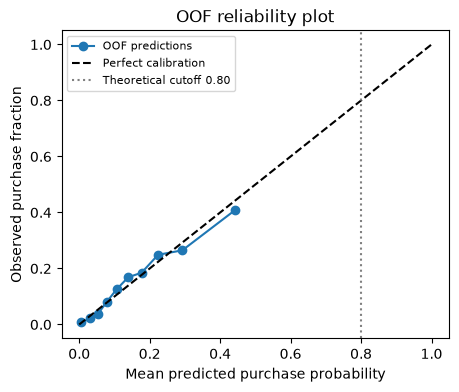

The theoretical 0.80 threshold is optimal for calibrated probabilities under A1–A3; finite-sample calibration and OOF selection can shift the empirical optimum.



**Computed threshold interpretation.** The OOF revenue-optimal cutoff is 0.8360, which is +0.0360 from the calibrated-probability reference 0.80. It assigns vouchers to 9,246 of 9,247 training sessions (99.99%). Only 2 OOF predictions are at or above 0.80. OOF Brier score is 0.1165; the mean absolute gap across the ten quantile reliability bins is 0.0172. With so few high-probability sessions and bins dominated by the low-probability range, this plot provides little evidence about calibration in the threshold tail. Thus the difference from 0.80 is consistent with a combination of finite-sample OOF variation and probability calibration error; it is not evidence of voucher effectiveness. Under guaranteed conversion, a high voucher share can follow from A1 itself.


In [17]:
# Reliability plot: bin predicted probabilities, then compare mean prediction with observed rate.
from sklearn.calibration import calibration_curve
obs,mean_pred=calibration_curve(ytr,P_TRAIN,n_bins=10,strategy='quantile')
fig,ax=plt.subplots(figsize=(5,4)); ax.plot(mean_pred,obs,'o-',label='OOF predictions'); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
ax.axvline(THEORY_THRESHOLD,color='grey',ls=':',label='Theoretical cutoff 0.80')
ax.set(xlabel='Mean predicted purchase probability',ylabel='Observed purchase fraction',title='OOF reliability plot')
ax.legend(fontsize=8); plt.show()
print('The theoretical 0.80 threshold is optimal for calibrated probabilities under A1–A3; finite-sample calibration and OOF selection can shift the empirical optimum.')
calibration_gap=float(np.mean(np.abs(obs-mean_pred)))
TRAIN_THRESHOLD_RESULT=revenue_at(ytr,P_TRAIN,T_OPT)
voucher_fraction=TRAIN_THRESHOLD_RESULT['voucher_count']/len(ytr)
above_theory=int(np.sum(P_TRAIN>=THEORY_THRESHOLD))
brier=brier_score_loss(ytr,P_TRAIN)
display(Markdown(f"""
**Computed threshold interpretation.** The OOF revenue-optimal cutoff is {T_OPT:.4f}, which is {T_OPT-THEORY_THRESHOLD:+.4f} from the calibrated-probability reference 0.80. It assigns vouchers to {TRAIN_THRESHOLD_RESULT['voucher_count']:,} of {len(ytr):,} training sessions ({voucher_fraction:.2%}). Only {above_theory:,} OOF predictions are at or above 0.80. OOF Brier score is {brier:.4f}; the mean absolute gap across the ten quantile reliability bins is {calibration_gap:.4f}. With so few high-probability sessions and bins dominated by the low-probability range, this plot provides little evidence about calibration in the threshold tail. Thus the difference from 0.80 is consistent with a combination of finite-sample OOF variation and probability calibration error; it is not evidence of voucher effectiveness. Under guaranteed conversion, a high voucher share can follow from A1 itself.
"""))


The threshold extension separates ranking from policy: changing the cutoff moves sensitivity and specificity along the selected model's ROC curve, while AUC stays fixed. The revenue plot follows the two stated scenarios and the unchanged baseline. Calibration departures and finite samples can explain why the empirical threshold differs from 0.80; the threshold is not chosen using test labels.

## 8. Extension: training CV versus historical test

**Objective.** Compare the selected candidate's fold-mean and pooled OOF AUC with its test AUC, then apply the fixed training-selected threshold to the historical test set. **Method:** fit the selected pipeline once on the full training partition, obtain test probabilities, and compute confusion outcomes. No model or threshold is retuned on test data.

In [18]:
FINAL_PIPE=clone(CONFIGS[WINNER]).fit(Xtr,ytr)
P_TEST=FINAL_PIPE.predict_proba(Xte)[:,1]
TRAIN_R=revenue_at(ytr,P_TRAIN,T_OPT); TEST_R=revenue_at(yte,P_TEST,T_OPT)
TEST_AUC=roc_auc_score(yte,P_TEST)
AUDIT=pd.DataFrame([
 {'evaluation':'Training OOF, pooled','AUC':roc_auc_score(ytr,P_TRAIN),**TRAIN_R},
 {'evaluation':'Historical test, fixed threshold','AUC':TEST_AUC,**TEST_R}
]).set_index('evaluation')
display(AUDIT.round(4))
print(f'Mean fold CV AUC: {CV_AUC:.4f}; pooled OOF AUC: {roc_auc_score(ytr,P_TRAIN):.4f}; test AUC: {TEST_AUC:.4f}')
print(f'Pooled OOF minus test AUC: {roc_auc_score(ytr,P_TRAIN)-TEST_AUC:+.4f}')
print('Test confusion matrix; rows=actual [0,1], columns=predicted Buy [0,1]:')
display(pd.DataFrame([[TEST_R['TN'],TEST_R['FP']],[TEST_R['FN'],TEST_R['TP']]],
    index=['Actual no purchase','Actual purchase'],columns=['Predicted no','Predicted Buy']))
cv_test_auc_gap=CV_AUC-TEST_AUC
if TEST_R['voucher_count']==len(yte):
    test_policy_note=(f"At this fixed cutoff the rule issues vouchers to every one of the {len(yte):,} historical test sessions (sensitivity {TEST_R['sensitivity']:.3f}, specificity {TEST_R['specificity']:.3f}); it makes no selective distinction on this partition. The simulated revenue result therefore follows from A1's guaranteed conversion assumption and is not evidence of classifier-driven real sales growth.")
else:
    test_policy_note=(f"The fixed rule issues vouchers to {TEST_R['voucher_count']:,} of {len(yte):,} historical test sessions ({TEST_R['voucher_count']/len(yte):.2%}); these figures remain conditional on A1 and do not establish classifier-driven real sales growth.")
display(Markdown(f"""
**Computed CV-to-test interpretation.** Mean fold AUC was {CV_AUC:.4f}, pooled OOF AUC was {roc_auc_score(ytr,P_TRAIN):.4f}, and historical test AUC was {TEST_AUC:.4f} (mean-fold minus test gap {cv_test_auc_gap:+.4f}). Sensitivity changed from {TRAIN_R['sensitivity']:.3f} in OOF training predictions to {TEST_R['sensitivity']:.3f} on test; specificity changed from {TRAIN_R['specificity']:.3f} to {TEST_R['specificity']:.3f}. These differences describe sample variation and possible selection optimism; the test partition was previously viewed, so it is not fresh independent confirmation.

{test_policy_note}
"""))


,AUC,TN,FP,FN,TP,sensitivity,specificity,R0_A,Rmodel_A,delta_A,relative_lift,voucher_count
evaluation,,,,,,,,,,,,
"Training OOF, pooled",0.7610,7816,0,1430,1,0.0007,1.0,1431.0,7397.8,5966.8,4.1697,9246
"Historical test, fixed threshold",0.7409,2606,0,477,0,0.0000,1.0,477.0,2466.4,1989.4,4.1706,3083


Mean fold CV AUC: 0.7615; pooled OOF AUC: 0.7610; test AUC: 0.7409
Pooled OOF minus test AUC: +0.0201
Test confusion matrix; rows=actual [0,1], columns=predicted Buy [0,1]:


,Predicted no,Predicted Buy
Actual no purchase,2606,0
Actual purchase,477,0



**Computed CV-to-test interpretation.** Mean fold AUC was 0.7615, pooled OOF AUC was 0.7610, and historical test AUC was 0.7409 (mean-fold minus test gap +0.0206). Sensitivity changed from 0.001 in OOF training predictions to 0.000 on test; specificity changed from 1.000 to 1.000. These differences describe sample variation and possible selection optimism; the test partition was previously viewed, so it is not fresh independent confirmation.

At this fixed cutoff the rule issues vouchers to every one of the 3,083 historical test sessions (sensitivity 0.000, specificity 1.000); it makes no selective distinction on this partition. The simulated revenue result therefore follows from A1's guaranteed conversion assumption and is not evidence of classifier-driven real sales growth.


### Test result interpretation and limitations

The dynamic interpretation below reports all four confusion outcomes and both revenue scenarios. Positive simulated revenue change means the model-guided policy exceeds the no-voucher baseline under A1–A4; it does not establish an actual voucher effect. Voucher counts include both actual buyers receiving an unnecessary discount (FN) and assumed conversions among non-buyers (TN).

**Limitations.** Voucher response is unobserved and guaranteed conversion is unverified. The dataset has no voucher predictor or intervention outcome; vouchers are hypothetical actions after classification. Results simulate sales revenue, not profitability; product costs, margins and operating costs are absent. Session predictors such as browsing duration, exit/bounce measures and `PageValues` may only be known at or after session completion; `PageValues` is excluded, but other predictor timing must be checked before real-time deployment. The observational unit is a session, and unique customer identities are unavailable, so repeated sessions cannot be grouped. The historical test partition was previously examined and is not fresh independent confirmation. Finally, selecting the model and threshold on the same OOF predictions makes OOF strategy revenue optimistic; a later independent evaluation would be needed for an unbiased estimate.

In [19]:
def business_sentence(name,r):
    verdict='higher' if r['delta_A']>1e-12 else ('lower' if r['delta_A'] < -1e-12 else 'equal')
    return (f"{name}: **R0={r['R0_A']:.1f}A**, **Rmodel={r['Rmodel_A']:.1f}A**, "
            f"**change={r['delta_A']:+.1f}A ({r['relative_lift']:+.2%})**; simulated revenue is {verdict} than baseline. "
            f"TP={r['TP']}, FP={r['FP']}, FN={r['FN']}, TN={r['TN']}; vouchers issued={r['voucher_count']:,}.")
display(Markdown(f"""
**Training OOF, selected threshold {T_OPT:.4f}.** {business_sentence('No-voucher versus model-guided',TRAIN_R)}

**Historical test, same fixed threshold.** {business_sentence('No-voucher versus model-guided',TEST_R)}

- **TP:** predicted Buy, actually Buy; no voucher and full-price purchase.
- **FP:** predicted Buy, actually No Buy; no voucher and a potential discounted conversion is missed.
- **FN:** predicted No Buy, actually Buy; voucher is issued although the session would have purchased without it.
- **TN:** predicted No Buy, actually No Buy; voucher is issued and converts under A1.

The no-voucher baseline is observed purchases (`TP+FN`) and is fixed for threshold comparisons. Simulated revenue uses `TP + 0.80(FN+TN)` in units of A. The labels remain unchanged. These results quantify the assumptions, not a forecast or causal effect.
"""))


**Training OOF, selected threshold 0.8360.** No-voucher versus model-guided: **R0=1431.0A**, **Rmodel=7397.8A**, **change=+5966.8A (+416.97%)**; simulated revenue is higher than baseline. TP=1, FP=0, FN=1430, TN=7816; vouchers issued=9,246.

**Historical test, same fixed threshold.** No-voucher versus model-guided: **R0=477.0A**, **Rmodel=2466.4A**, **change=+1989.4A (+417.06%)**; simulated revenue is higher than baseline. TP=0, FP=0, FN=477, TN=2606; vouchers issued=3,083.

- **TP:** predicted Buy, actually Buy; no voucher and full-price purchase.
- **FP:** predicted Buy, actually No Buy; no voucher and a potential discounted conversion is missed.
- **FN:** predicted No Buy, actually Buy; voucher is issued although the session would have purchased without it.
- **TN:** predicted No Buy, actually No Buy; voucher is issued and converts under A1.

The no-voucher baseline is observed purchases (`TP+FN`) and is fixed for threshold comparisons. Simulated revenue uses `TP + 0.80(FN+TN)` in units of A. The labels remain unchanged. These results quantify the assumptions, not a forecast or causal effect.


## 9. Conclusion and machine-readable project summary

**Interpretation.** The final dynamic display consolidates model choice, threshold, discrimination, confusion outcomes and the two required revenue scenarios. Cross-validation and test AUC describe discrimination; simulated revenue describes the thresholded policy under the stated assumptions. They answer different questions.

In [20]:
def json_number(value):
    if value is None or not np.isfinite(value): return None
    return float(value) if isinstance(value,(float,np.floating)) else int(value)
def summary_metrics(r):
    return {k:json_number(r[k]) for k in ['TP','FP','FN','TN','sensitivity','specificity',
        'voucher_count','R0_A','Rmodel_A','delta_A','relative_lift']}
SUMMARY={
 'selected_candidate':WINNER,
 'threshold':json_number(T_OPT),
 'mean_cv_auc':json_number(CV_AUC),
 'pooled_oof_auc':json_number(roc_auc_score(ytr,P_TRAIN)),
 'test_auc':json_number(TEST_AUC),
 'training_oof':summary_metrics(TRAIN_R),
 'historical_test':summary_metrics(TEST_R),
 'candidate_designs':int(len(LEDGER)),
 'successful_candidates':int(LED.status.eq('OK').sum()),
 'failed_candidates':int(LED.status.eq('FAILED').sum()),
 'cost_ratio_FN_to_FP':'1:4',
 'assumptions':['A1 guaranteed conversion','A2 20% discount','A3 common order value A','A4 observed labels are no-voucher behaviour']}
print('PROJECT SUMMARY — JSON\n' + json.dumps(SUMMARY,indent=2,allow_nan=False))

PROJECT SUMMARY — JSON
{
  "selected_candidate": "Logistic | quantile",
  "threshold": 0.8359523283877723,
  "mean_cv_auc": 0.7614554421909258,
  "pooled_oof_auc": 0.7610129054915751,
  "test_auc": 0.7408914438700563,
  "training_oof": {
    "TP": 1,
    "FP": 0,
    "FN": 1430,
    "TN": 7816,
    "sensitivity": 0.0006988120195667365,
    "specificity": 1.0,
    "voucher_count": 9246,
    "R0_A": 1431.0,
    "Rmodel_A": 7397.8,
    "delta_A": 5966.8,
    "relative_lift": 4.169671558350804
  },
  "historical_test": {
    "TP": 0,
    "FP": 0,
    "FN": 477,
    "TN": 2606,
    "sensitivity": 0.0,
    "specificity": 1.0,
    "voucher_count": 3083,
    "R0_A": 477.0,
    "Rmodel_A": 2466.4,
    "delta_A": 1989.4,
    "relative_lift": 4.170649895178197
  },
  "candidate_designs": 29,
  "successful_candidates": 27,
  "failed_candidates": 2,
  "cost_ratio_FN_to_FP": "1:4",
  "assumptions": [
    "A1 guaranteed conversion",
    "A2 20% discount",
    "A3 common order value A",
    "A4 observ